# Locally weighted linear regression — a one-feature demo

This notebook shows what the `LocallyWeightedRegressor` from `lwlr.py` does as its two
hyper-parameters change.

* **`alpha`** controls locality: how fast a training point's weight falls off with its
  distance from the query point ($w_i = \exp(-\alpha\,|x_i - x|)$). `alpha = 0` weights all
  points equally.
* **`rho`** controls how strongly the slope is pulled to zero. `rho = 0` is a full local linear
  fit; `rho = 1` drops the slope and predicts the weighted average of the targets.

The data has a single feature $x$ and a target

$$
y = c + k\,x + a\,\sin(x) + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, \sigma^2).
$$

A straight line cannot follow the $\sin$ part, so you can see where the local fit helps
and where a plain weighted average falls short.

Every prediction in this notebook is made **leave-one-out**: to predict point $i$ the model
is fitted on all points except $i$. This matters because the model is a memoriser — with a
large `alpha` and the point itself in the training set, it would simply return $y_i$ and look
perfect. Leave-one-out shows what the model does on data it has not seen.

**How to use it.** Change the values in the *Settings* cell below and run all cells.

In [1]:
import itertools

import numpy as np
import matplotlib.pyplot as plt

from lwlr import LocallyWeightedRegressor

# Colours: grey for the data, blue for the model, orange for the true function.
C_DATA, C_MODEL, C_TRUE = "#9a9a96", "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e3",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7",
    "axes.titlesize": 10,
})

## Settings

Everything you are expected to play with is in this cell.

* `X_MIN`, `X_MAX` — range of the feature. One period of $\sin$ is about $6.28$, so a range of
  width $12$ gives two full waves.
* `N_POINTS` — number of data points, drawn uniformly at random from the range.
* `NOISE_STD` — standard deviation $\sigma$ of the Gaussian noise added to $y$.
* `C`, `K`, `A` — the constants in $y = c + k\,x + a\,\sin(x)$.
* `ALPHAS`, `RHOS` — the hyper-parameter values to try. **All combinations** are evaluated,
  so the number of plots is `len(ALPHAS) * len(RHOS)`. Keep the extremes (`0` in both
  lists, `1` in `RHOS`, something large in `ALPHAS`) to see the corner cases.

In [42]:
# --- data ---------------------------------------------------------------
X_MIN, X_MAX = 0.0, 20.0
N_POINTS = 100
NOISE_STD = 2.0
C, K, A = 1.0, 1.0, 3.0
SEED = 0

# --- hyper-parameters to try (all combinations are used) -----------------
ALPHAS = [0.0, 0.5, 1.0, 3.0, 10.0]
RHOS = [0.0, 0.5, 0.9, 1.0]

## Generate the dataset

The true function (without noise) is drawn as a dashed orange line so you can compare the
model against it later.

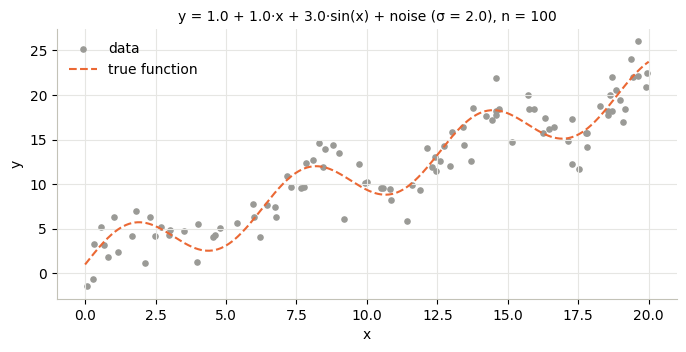

In [43]:
def true_function(x):
    return C + K * x + A * np.sin(x)


rng = np.random.default_rng(SEED)
x = np.sort(rng.uniform(X_MIN, X_MAX, size=N_POINTS))
y = true_function(x) + rng.normal(0.0, NOISE_STD, size=N_POINTS)

X = x[:, None]                     # the model expects a 2D feature matrix
x_grid = np.linspace(X_MIN, X_MAX, 400)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(x, y, s=14, color=C_DATA, label="data")
ax.plot(x_grid, true_function(x_grid), "--", lw=1.5, color=C_TRUE, label="true function")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"y = {C} + {K}·x + {A}·sin(x) + noise (σ = {NOISE_STD}), n = {N_POINTS}")
ax.legend(frameon=False)
plt.show()

## Leave-one-out prediction

For each point $i$ the model is fitted on the other $n-1$ points and asked to predict $x_i$.
The function below returns the vector of these predictions, one per data point.
`fit` only stores the data, so refitting $n$ times is cheap.

In [44]:
def leave_one_out_predict(alpha, rho, X, y):
    n = len(y)
    preds = np.empty(n)
    mask = np.ones(n, dtype=bool)
    for i in range(n):
        mask[i] = False
        model = LocallyWeightedRegressor(alpha=alpha, rho=rho).fit(X[mask], y[mask])
        preds[i] = model.predict(X[i : i + 1])[0]
        mask[i] = True
    return preds


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

## All combinations of `alpha` and `rho`

One panel per combination. Rows share an `alpha`, columns share a `rho`. In every panel:

* grey dots — the data,
* dashed orange line — the true function without noise,
* blue line — the leave-one-out predictions, joined in order of $x$.

The title of each panel gives the leave-one-out RMSE against the noisy targets. The noise
floor is `NOISE_STD`; a model cannot do better than that on average.

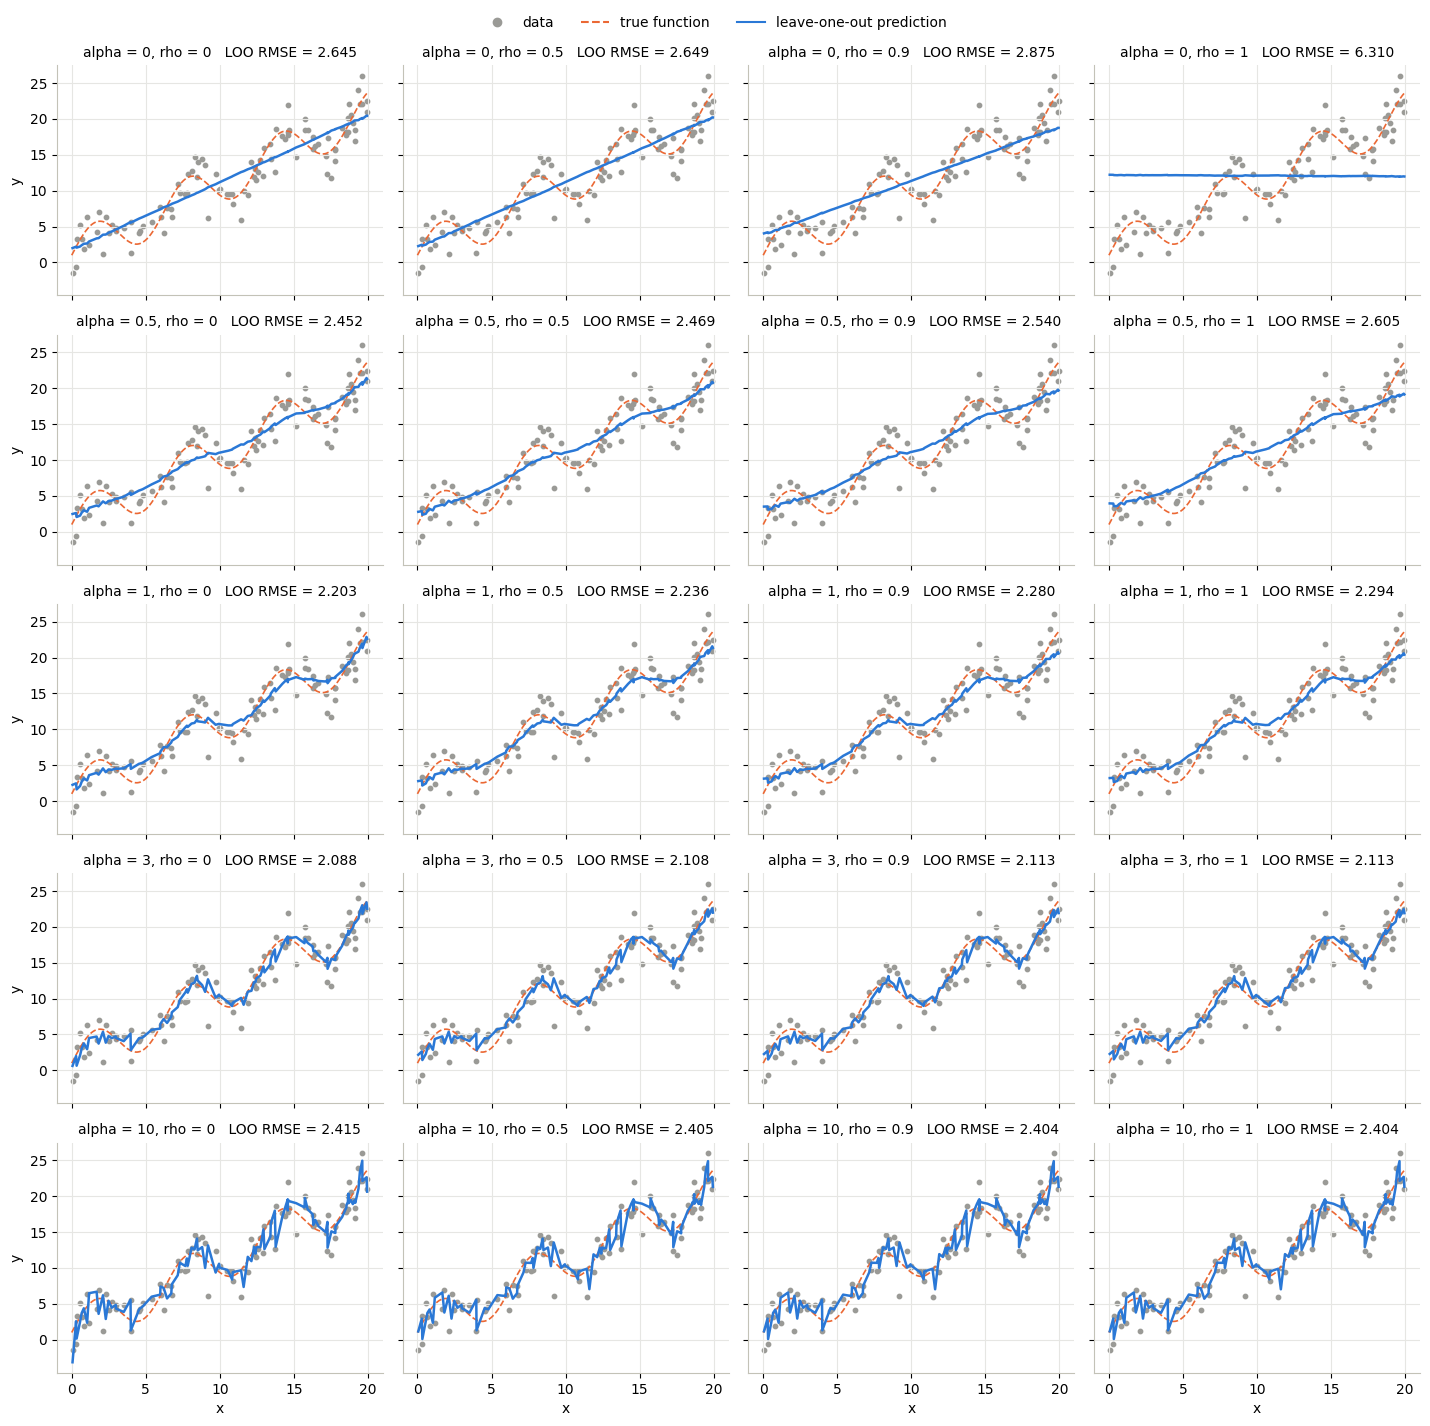

In [45]:
results = {}
for alpha, rho in itertools.product(ALPHAS, RHOS):
    results[(alpha, rho)] = leave_one_out_predict(alpha, rho, X, y)

n_rows, n_cols = len(ALPHAS), len(RHOS)
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(3.6 * n_cols, 2.8 * n_rows),
    sharex=True, sharey=True, squeeze=False,
)

for (r, alpha), (c, rho) in itertools.product(enumerate(ALPHAS), enumerate(RHOS)):
    ax = axes[r, c]
    pred = results[(alpha, rho)]
    ax.scatter(x, y, s=10, color=C_DATA)
    ax.plot(x_grid, true_function(x_grid), "--", lw=1.2, color=C_TRUE)
    ax.plot(x, pred, lw=1.8, color=C_MODEL)
    ax.set_title(f"alpha = {alpha:g}, rho = {rho:g}   LOO RMSE = {rmse(pred, y):.3f}")
    if r == n_rows - 1:
        ax.set_xlabel("x")
    if c == 0:
        ax.set_ylabel("y")

handles = [
    plt.Line2D([], [], marker="o", ls="", color=C_DATA, label="data"),
    plt.Line2D([], [], ls="--", color=C_TRUE, label="true function"),
    plt.Line2D([], [], ls="-", color=C_MODEL, label="leave-one-out prediction"),
]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()
plt.show()

## Leave-one-out RMSE for every combination

The same numbers as in the panel titles, as a table (rows: `alpha`, columns: `rho`).
The best combination is marked with `*`.

In [46]:
scores = {key: rmse(pred, y) for key, pred in results.items()}
best = min(scores, key=scores.get)

header = "alpha \\ rho".ljust(12) + "".join(f"{rho:>10g}" for rho in RHOS)
print(header)
print("-" * len(header))
for alpha in ALPHAS:
    row = f"{alpha:<12g}"
    for rho in RHOS:
        mark = "*" if (alpha, rho) == best else " "
        row += f"{scores[(alpha, rho)]:>9.3f}{mark}"
    print(row)
print(f"\nnoise level (sigma): {NOISE_STD:.3f}")
print(f"best: alpha = {best[0]:g}, rho = {best[1]:g}, LOO RMSE = {scores[best]:.3f}")

alpha \ rho          0       0.5       0.9         1
----------------------------------------------------
0               2.645     2.649     2.875     6.310 
0.5             2.452     2.469     2.540     2.605 
1               2.203     2.236     2.280     2.294 
3               2.088*    2.108     2.113     2.113 
10              2.415     2.405     2.404     2.404 

noise level (sigma): 2.000
best: alpha = 3, rho = 0, LOO RMSE = 2.088


## What to look for

* **`alpha = 0, rho = 0`** is ordinary linear regression: one straight line through all the
  data. It gets the trend $c + k\,x$ but cannot bend to follow the $\sin$ part.
* **`alpha = 0, rho = 1`** predicts the global mean everywhere: a flat line.
* **`alpha > 0, rho = 0`** is the local linear fit. With a moderate `alpha` it follows the
  waves and stays close to the true function, including at the two ends of the range.
* **`alpha > 0, rho = 1`** is the kernel-weighted average (a soft nearest-neighbour model). With
  a moderate `alpha` it also follows the waves, but it is pulled towards the mean of its
  neighbours and so lags behind the true function wherever it has a slope — most visibly at the
  two ends, where all the neighbours lie on one side.
* **Large `alpha`** with any `rho` makes the prediction depend on very few points. The blue line
  starts to chase the noise; with `rho = 1` and a very large `alpha` it becomes 1-nearest
  neighbour and simply copies the nearest neighbour's noisy value.
* **Intermediate `rho`** values interpolate between the local line and the local average.

Try a smaller `N_POINTS` or a larger `NOISE_STD` to see the large-`alpha` panels fall apart, or
a larger range to see how many points the local fit needs per wave.